Import Libraries

In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from scipy import stats
from scipy.stats import chi2_contingency, f_oneway

sns.set_theme(style= 'whitegrid')
pd.set_option("display.max_columns", None)

Load cleaned datasets

In [ ]:
students = pd.read_csv("../Cleaned_Data/Students_Cleaned.csv")
courses = pd.read_csv("../Cleaned_Data/Course_Catalogue_Cleaned.csv")
interactions = pd.read_csv(
    "../Cleaned_Data/Student_Course_Interactions_Cleaned.csv"
)

# Convert dates
students["Survey_Timestamp"] = pd.to_datetime(
    students["Survey_Timestamp"], errors="coerce"
)

interactions["Interaction_Date"] = pd.to_datetime(
    interactions["Interaction_Date"], errors="coerce"
)

print("Cleaned datasets loaded successfully!")

print("Students:", students.shape)
print("Courses:", courses.shape)
print("Interactions:", interactions.shape)


Cleaned datasets loaded successfully!
Students: (980, 33)
Courses: (178, 20)
Interactions: (5755, 10)



Categorical values standardize

In [ ]:
# Standardize text columns
students["Gender"] = (
    students["Gender"]
    .astype("string")
    .str.strip()
    .str.lower()
)

students["Skill_Level"] = (
    students["Skill_Level"]
    .astype("string")
    .str.strip()
    .str.lower()
)

students["Internship_Experience"] = (
    students["Internship_Experience"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Standardize Gender
gender_map = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "femal": "Female",
    "female": "Female"
}

students["Gender"] = (
    students["Gender"].map(gender_map).fillna("Unknown")
)

# Standardize Skill Level
skill_map = {
    "intermediate": "Intermediate",
    "intermed.": "Intermediate",
    "medium": "Intermediate",
    "mid": "Intermediate",
    "advanced": "Advanced",
    "advance": "Advanced",
    "adv.": "Advanced",
    "beginner": "Beginner"
}

students["Skill_Level"] = (
    students["Skill_Level"].map(skill_map).fillna("Unknown")
)

# Standardize Internship Experience
internship_map = {
    "1": "Yes",
    "true": "Yes",
    "yes": "Yes",
    "y": "Yes",
    "0": "No",
    "false": "No",
    "no": "No",
    "n": "No"
}

students["Internship_Experience"] = (
    students["Internship_Experience"]
    .map(internship_map)
    .fillna("Unknown")
)

Handle Missing values

In [ ]:
# Check missing values
print("Students:\n", students.isnull().sum())
print("\nCourses:\n", courses.isnull().sum())
print("\nInteractions:\n", interactions.isnull().sum())

# Numerical columns
num_cols = students.select_dtypes(include="number").columns

for col in num_cols:
    students[col] = students[col].fillna(students[col].median())

# Categorical columns
cat_cols = students.select_dtypes(
    include=["object", "string"]
).columns

for col in cat_cols:
    if students[col].isnull().sum() > 0:
        mode_value = students[col].mode()
        if not mode_value.empty:
            students[col] = students[col].fillna(mode_value[0])


Students:
 Student_ID                        0
Batch_Year                        1
Semester                          0
Branch                            0
School                            1
Campus                            0
Age                               0
Gender                            0
Class12_Stream                    2
CGPA                              0
Previous_Semester_SGPA            0
Attendance_Percentage             0
Weekly_Study_Hours                0
Num_Prior_Exploratory_Courses     0
Num_Certifications                0
Internship_Experience             0
Interests                         1
Secondary_Interests               3
Hobbies                           2
Technical_Skills                  2
Skill_Level                       0
Career_Goal                       0
Learning_Preference               2
Preferred_Difficulty              3
Workload_Preference               0
Preferred_Slot                    2
Confusion_Level                   0
Confusion_Reason

Check Invalid values

In [ ]:
# Check CGPA range
print("Invalid CGPA values:")
print(students[
    (students["CGPA"] < 0) |
    (students["CGPA"] > 10)
])

# Check Attendance range
print("\nInvalid Attendance values:")
print(students[
    (students["Attendance_Percentage"] < 0) |
    (students["Attendance_Percentage"] > 100)
])


Invalid CGPA values:
Empty DataFrame
Columns: [Student_ID, Batch_Year, Semester, Branch, School, Campus, Age, Gender, Class12_Stream, CGPA, Previous_Semester_SGPA, Attendance_Percentage, Weekly_Study_Hours, Num_Prior_Exploratory_Courses, Num_Certifications, Internship_Experience, Interests, Secondary_Interests, Hobbies, Technical_Skills, Skill_Level, Career_Goal, Learning_Preference, Preferred_Difficulty, Workload_Preference, Preferred_Slot, Confusion_Level, Confusion_Reason, Selection_Confidence, Previous_Course_Satisfaction, Survey_Timestamp, Selected_Course_Code, Selected_Exploratory_Course]
Index: []

Invalid Attendance values:
Empty DataFrame
Columns: [Student_ID, Batch_Year, Semester, Branch, School, Campus, Age, Gender, Class12_Stream, CGPA, Previous_Semester_SGPA, Attendance_Percentage, Weekly_Study_Hours, Num_Prior_Exploratory_Courses, Num_Certifications, Internship_Experience, Interests, Secondary_Interests, Hobbies, Technical_Skills, Skill_Level, Career_Goal, Learning_Prefe

Check Duplicate records

In [ ]:
print("Student duplicate rows:", students.duplicated().sum())
print("Course duplicate rows:", courses.duplicated().sum())
print("Interaction duplicate rows:", interactions.duplicated().sum())


Student duplicate rows: 0
Course duplicate rows: 0
Interaction duplicate rows: 0



Correction of data columns

In [ ]:
students["Survey_Timestamp"] = pd.to_datetime(
    students["Survey_Timestamp"], errors="coerce"
)
# Flag suspicious dates
print(students[
    students["Survey_Timestamp"] < "2026-01-01"
][["Survey_Timestamp"]])


    Survey_Timestamp
124       1970-01-01



Check invalid interaction data duration

In [ ]:
# Check interaction time duration

print("Time Spent Minutes Summary:")
print(interactions["Time_Spent_Minutes"].describe())

# Check negative duration values
print("\nNegative Duration Records:")
print(interactions[
    interactions["Time_Spent_Minutes"] < 0
])

# Check unusually high duration values
Q1 = interactions["Time_Spent_Minutes"].quantile(0.25)
Q3 = interactions["Time_Spent_Minutes"].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print("\nPotential High Outliers:")
print(interactions[
    interactions["Time_Spent_Minutes"] > upper_limit
])


Time Spent Minutes Summary:
count    5755.000000
mean       42.148045
std       547.764062
min         0.000000
25%         3.000000
50%         5.000000
75%         8.000000
max      9999.000000
Name: Time_Spent_Minutes, dtype: float64

Negative Duration Records:
Empty DataFrame
Columns: [Interaction_ID, Student_ID, Course_ID, Course_Code, Interaction_Type, Interaction_Date, Time_Spent_Minutes, Recommended_By, Rating_Given, Suitability_Label]
Index: []

Potential High Outliers:
     Interaction_ID Student_ID Course_ID Course_Code Interaction_Type  \
13         INT00014    STU0003      C047    ECEG2059         compared   
25         INT00026    STU0004      C174    HRES2014      shortlisted   
28         INT00029    STU0005      C027    CLCC1004      shortlisted   
29         INT00030    STU0005      C003    LSHP2003         compared   
34         INT00035    STU0006      C175    INTB3019      shortlisted   
...             ...        ...       ...         ...              ...   
5644

Basic statistical overview

In [ ]:
print("Student Dataset Summary")
display(students.describe(include="all").T)

print("Course dataset summary")
display(courses.describe(include="all").T)

print("Interaction dataset summary")
display(interactions.describe(include="all").T)


Student Dataset Summary



,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Student_ID,980,960,STU0234,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Batch_Year,980,10,2025,444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Semester,980,23,3,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Branch,980,148,B.Tech CSE - Data Science,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
School,980,31,SOCS,262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Campus,980,13,Bidholi,460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,980.0,NaN,NaN,NaN,20.264286,17.0,20.0,20.0,21.0,27.0,1.009935
Gender,980,3,Male,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class12_Stream,980,16,pcm,523,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CGPA,980.0,NaN,NaN,NaN,7.533071,0.0,6.9775,7.59,8.14,10.0,1.071788



Course dataset summary



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Course_ID,178,178,C001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AY,178.0,NaN,NaN,NaN,2024.224719,0.724905,2023.0,2024.0,2024.0,2025.0,2025.0
School,178,7,SOAE,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sem,178,10,3,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Course Code,178,156,ECEG2059,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Course,178,155,Industrial Power Electronics,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CREDIT,178.0,NaN,NaN,NaN,3.134831,0.491533,2.0,3.0,3.0,3.0,6.0
Minor Stream,178,47,Minor in Electronics Engineering,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Slot,178,3,Slot 1,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Schedule,178,5,Monday to Wednesday- 11:00 AM to 12:00 Noon,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Interaction dataset summary



,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Interaction_ID,5755,5733,INT00207,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Student_ID,5755,1074,STU0516,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Course_ID,5755,166,C037,169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Course_Code,5755,200,CSIB1002,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Interaction_Type,5755,13,viewed,2272,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Interaction_Date,5696,NaN,NaN,NaN,2026-08-26 09:37:55.114290688,2026-01-01 10:00:00,2026-08-03 15:29:46.500000,2026-08-28 23:45:30,2026-09-24 00:00:00,2027-01-10 00:00:00,NaN
Time_Spent_Minutes,5755.0,NaN,NaN,NaN,42.148045,0.0,3.0,5.0,8.0,9999.0,547.764062
Recommended_By,5748,19,self-search,1669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating_Given,1127.0,NaN,NaN,NaN,4.038154,1.0,3.0,4.0,5.0,5.0,1.001491
Suitability_Label,5497,9,high,2121,NaN,NaN,NaN,NaN,NaN,NaN,NaN


STUDENT DEMOGRAPHIC ANALYSIS

Student distribution by gender


Gender
Male       644
Female     327
Unknown      9
Name: count, dtype: int64


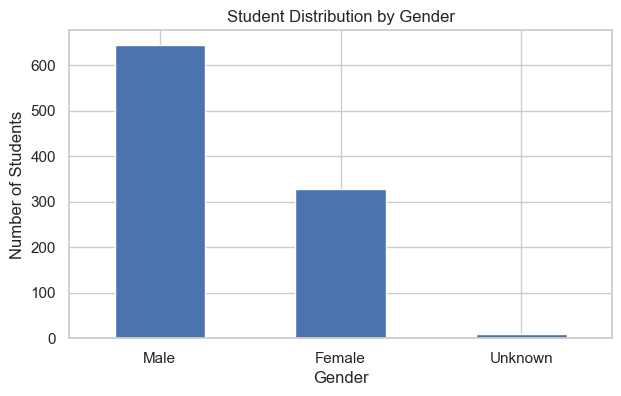

In [ ]:
gender_counts = students["Gender"].value_counts()
display(gender_counts)
gender_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Student Distribution by Gender"
)
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

Student distribution by branch

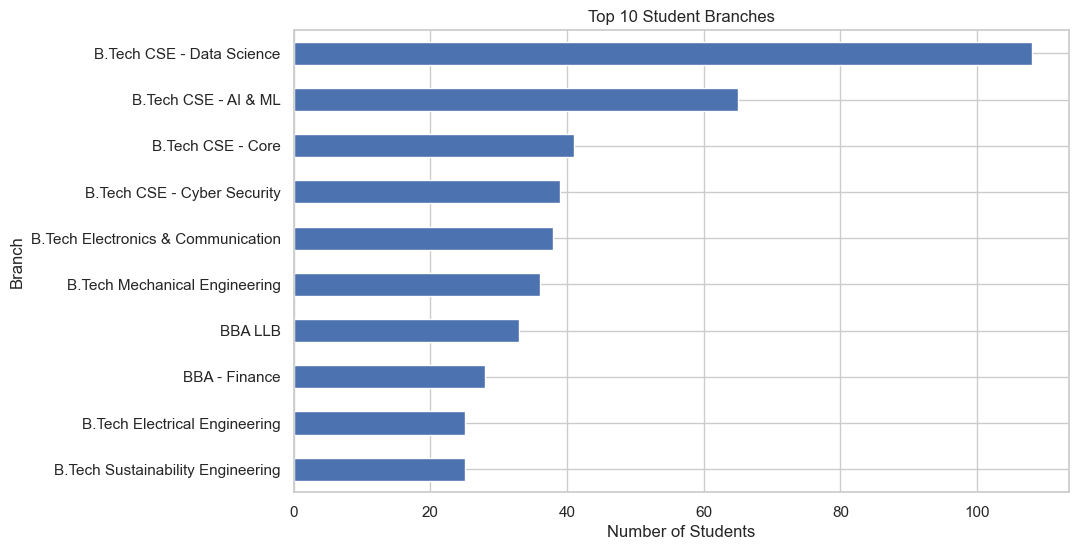

In [ ]:
branch_counts = students["Branch"].value_counts().head(10)
branch_counts.plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Student Branches"
)

plt.xlabel("Number of Students")
plt.ylabel("Branch")
plt.gca().invert_yaxis()
plt.show()

Age Distribution

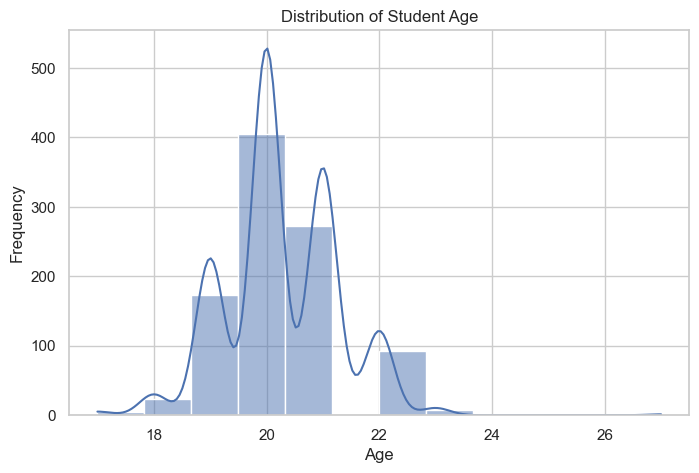

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=students,
    x="Age",
    bins=12,
    kde=True
)
plt.title("Distribution of Student Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

ACADEMIC PERFORMANCE ANALYSIS

CGPA distribution

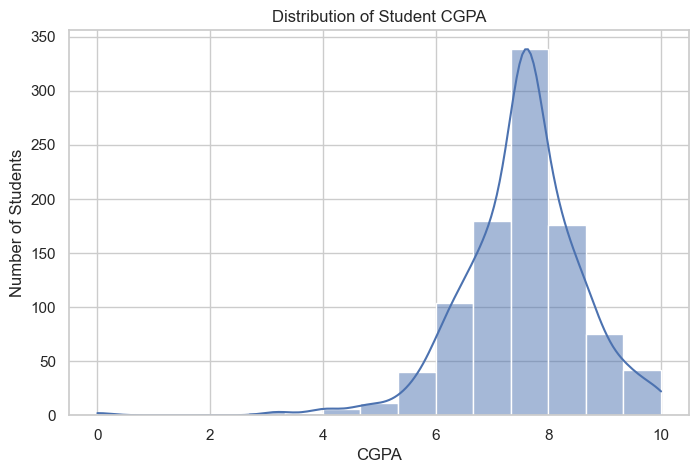

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=students,
    x="CGPA",
    bins=15,
    kde=True
)
plt.title("Distribution of Student CGPA")
plt.xlabel("CGPA")
plt.ylabel("Number of Students")
plt.show()

CGPA by branch

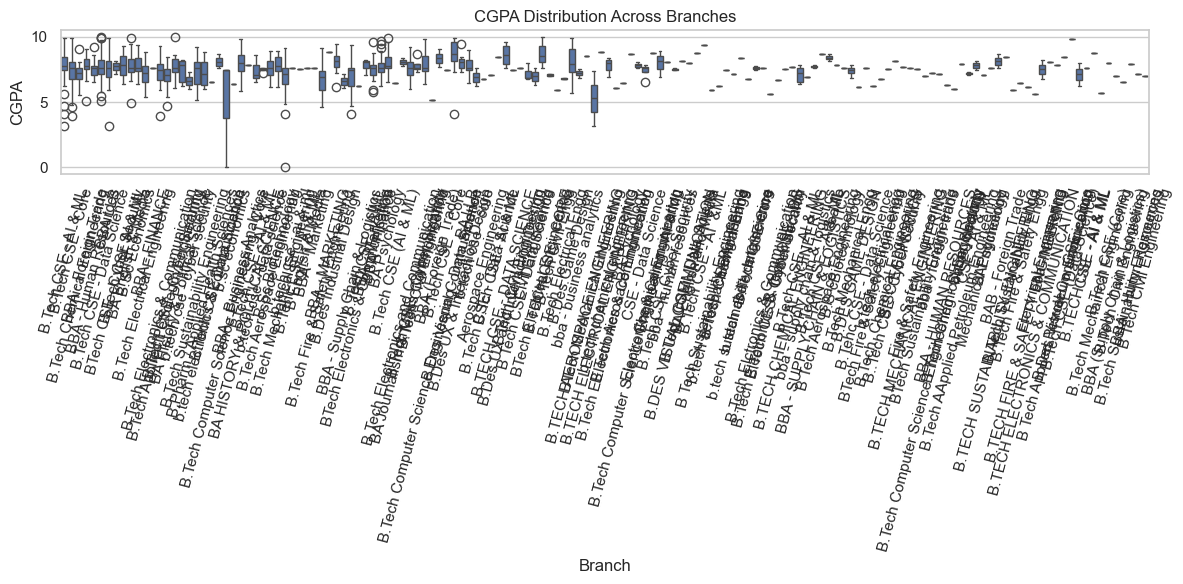

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=students,
    x="Branch",
    y="CGPA"
)
plt.title("CGPA Distribution Across Branches")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

Attendance versus CGPA

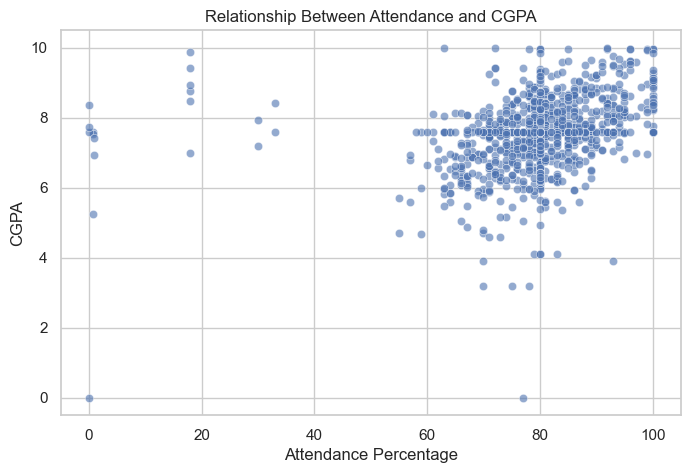

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=students,
    x="Attendance_Percentage",
    y="CGPA",
    alpha=0.6
)
plt.title("Relationship Between Attendance and CGPA")
plt.xlabel("Attendance Percentage")
plt.ylabel("CGPA")
plt.show()

STUDENT INTERESTS AND PREFERENCES

Skill level distribution


Skill_Level
Intermediate    404
Advanced        277
Beginner        217
Unknown          82
Name: count, dtype: int64


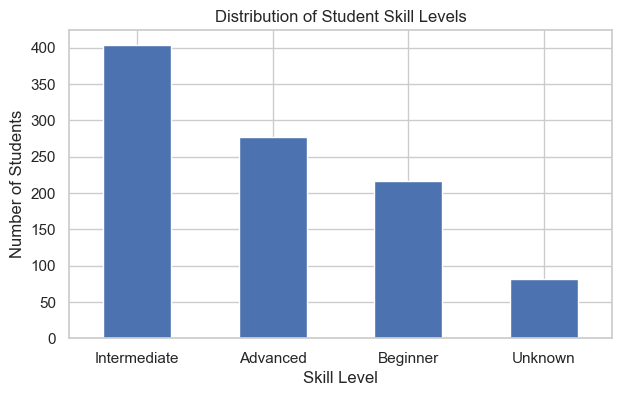

In [ ]:
skill_counts = students["Skill_Level"].value_counts()
display(skill_counts)
skill_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Distribution of Student Skill Levels"
)
plt.xlabel("Skill Level")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

Learning preferences

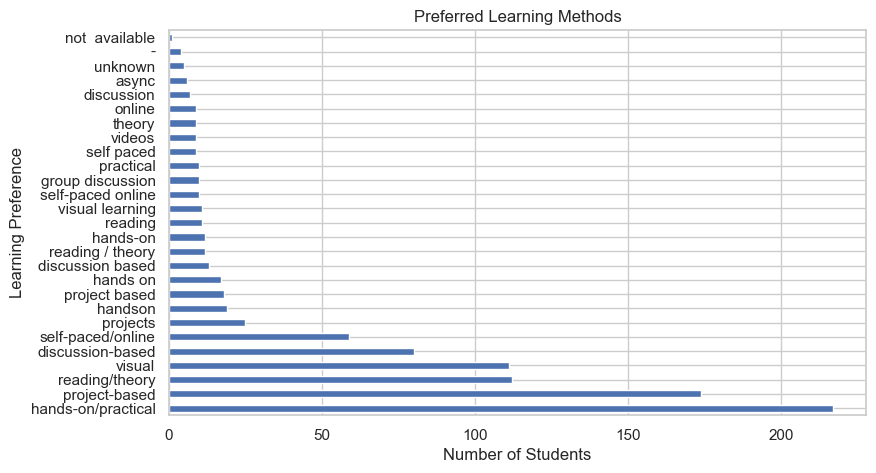

In [ ]:
learning_counts = students["Learning_Preference"].value_counts()
learning_counts.plot(
    kind="barh",
    figsize=(9, 5),
    title="Preferred Learning Methods"
)
plt.xlabel("Number of Students")
plt.ylabel("Learning Preference")
plt.show()

Confusion level

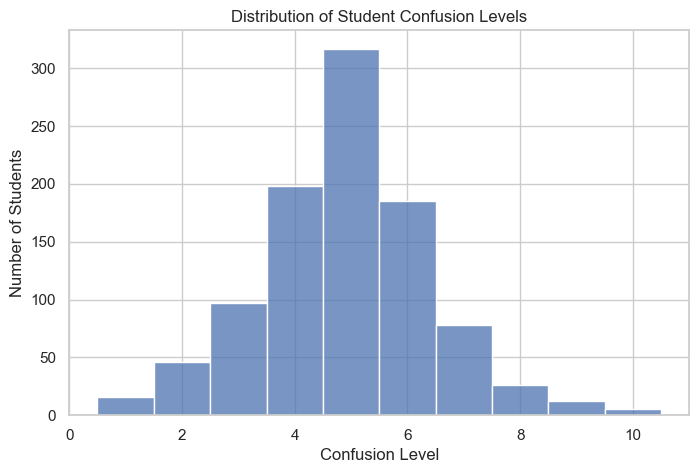

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=students,
    x="Confusion_Level",
    bins=10,
    discrete=True
)
plt.title("Distribution of Student Confusion Levels")
plt.xlabel("Confusion Level")
plt.ylabel("Number of Students")
plt.show()

Most common interests


Interests
Design & UX                                   109
Data Analytics                                 94
Programming & Software Development             90
Mathematics                                    77
Artificial Intelligence & Machine Learning     71
Law                                            69
Finance & Banking                              65
Safety & Risk                                  64
Energy & Sustainability                        62
Economics                                      56
Name: count, dtype: int64


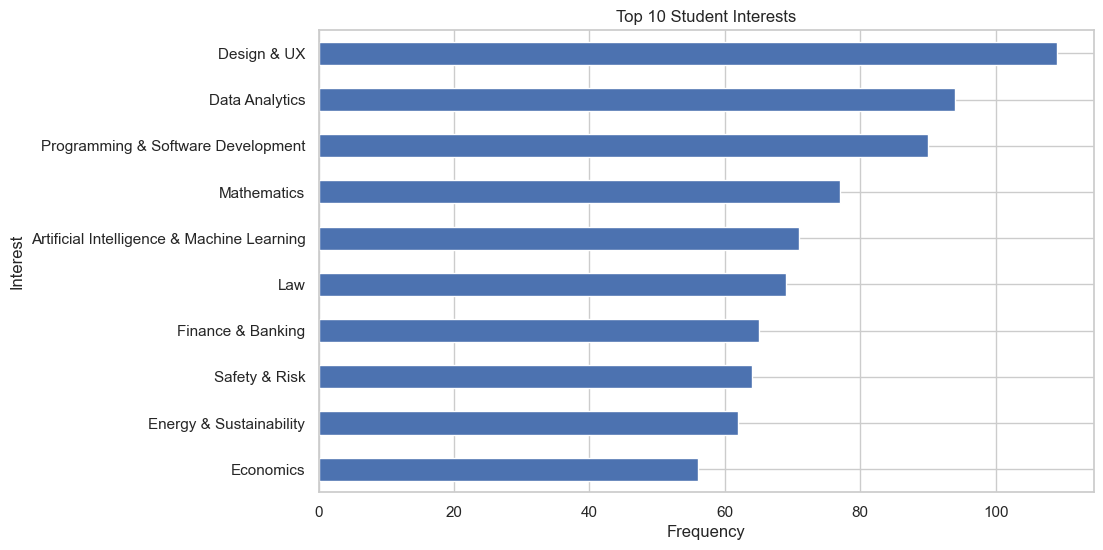

In [ ]:
interest_list = (
    students["Interests"]
    .dropna()
    .str.split(r"[;,]")
    .explode()
    .str.strip()
)
interest_counts = interest_list.value_counts().head(10)
display(interest_counts)
interest_counts.plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Student Interests"
)
plt.xlabel("Frequency")
plt.ylabel("Interest")
plt.gca().invert_yaxis()
plt.show()

COURSE SELECTION ANALYSIS

Most selected courses


Selected_Course_Code
CSIB1002     79
SCS20A001    35
DSBA2010     25
DSIT3007P    24
LSAS1003     20
DSBA2006P    17
SDGM2041     15
ECEG4033     15
CSEG2079     14
SMDM3002     14
Name: count, dtype: int64


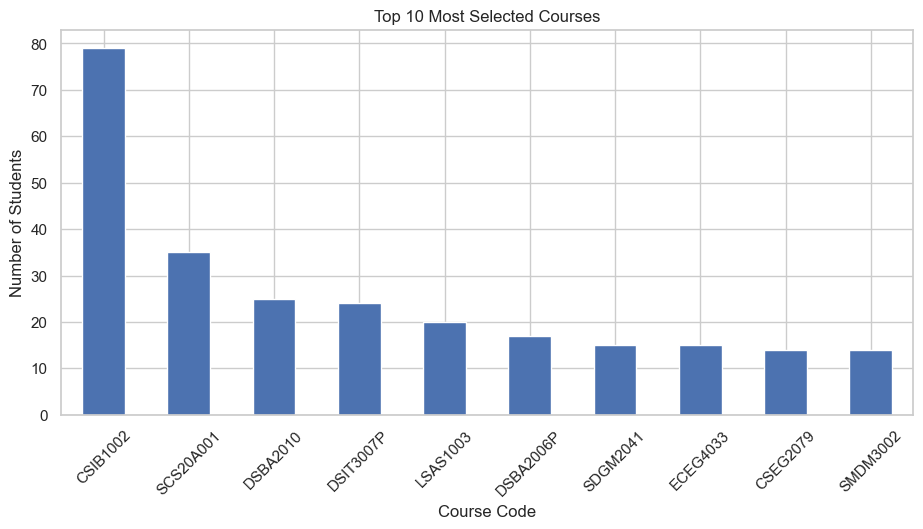

In [ ]:
selected_courses = (
    students["Selected_Course_Code"]
    .dropna()
    .value_counts()
    .head(10)
)
display(selected_courses)
selected_courses.plot(
    kind="bar",
    figsize=(11, 5),
    title="Top 10 Most Selected Courses"
)
plt.xlabel("Course Code")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.show()

Course codes with course names

In [ ]:
course_selection = (
    students["Selected_Course_Code"]
    .value_counts()
    .rename_axis("Course Code")
    .reset_index(name="Student Count")
)
course_selection = course_selection.merge(
    courses[["Course Code", "Course", "Primary_Domain"]],
    on="Course Code",
    how="left"
)
display(course_selection.head(15))

,Course Code,Student Count,Course,Primary_Domain
0,CSIB1002,79,Python Programming,Programming & Software Development
1,SCS20A001,35,Data Visualization,Data Analytics
2,DSBA2010,25,Data Management,Data Analytics
3,DSIT3007P,24,Data Visualization,Data Analytics
4,LSAS1003,20,Calculus I,Mathematics
5,DSBA2006P,17,Overview of Programming for Analytics,Programming & Software Development
6,SDGM2041,15,Introduction to Game Design,Gaming & Film
7,ECEG4033,15,E-Vehicle,Electrical Systems & EVs
8,ECEG4033,15,E-Vehicle,Electrical Systems & EVs
9,CSEG2079,14,Data Structures and Algorithms,Programming & Software Development


Popular course domains


Primary_Domain
Programming & Software Development    143
Data Analytics                        124
Electronics & IoT                      95
Design & UX                            78
Electrical Systems & EVs               64
Energy & Sustainability                64
Law                                    57
Media & Journalism                     44
Finance & Banking                      41
Marketing                              31
Name: Student Count, dtype: int64


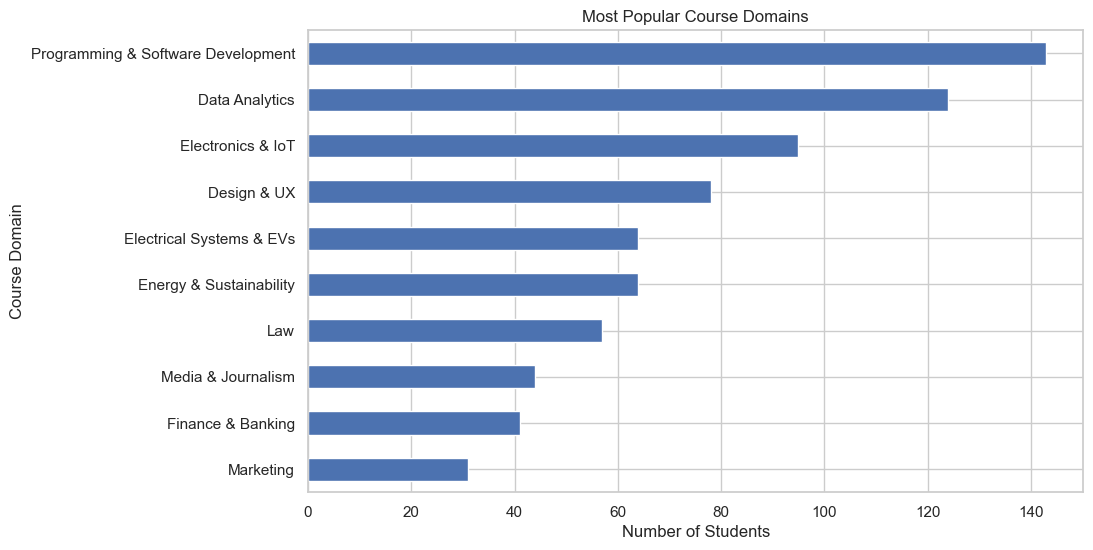

In [ ]:
domain_counts = course_selection.groupby(
    "Primary_Domain"
)["Student Count"].sum().sort_values(ascending=False).head(10)
display(domain_counts)
domain_counts.plot(
    kind="barh",
    figsize=(10, 6),
    title="Most Popular Course Domains"
)
plt.xlabel("Number of Students")
plt.ylabel("Course Domain")
plt.gca().invert_yaxis()
plt.show()

Course selection by skill level

In [ ]:
selection_skill = pd.crosstab(
    students["Skill_Level"],
    students["Selected_Exploratory_Course"]
)
display(selection_skill)

Selected_Exploratory_Course,- Data Visualization,0000 - Electrical Machines,AEAT,AEI,AI & Multimedia,AI Economies and Game Eco-systems,AI and Multimedia,AI-assisted 3D visualization,AI-assisted 3D visualization,AI-sasisted 3D visualization,Advances in GIS Technologies,Aeronautics aand Astronautics: A Systems Perspective,Aeronautics and Astron...,Aeronautics and Astronautics: A Systems Perspective,Analog Electronics II,Analog EElectronics II,Analog Electronics II,Applied IR and Geopolitics,Automotive Engineering and Technology,Basics of Cultural Studies,Basics of Privacy & Cyber Security,Basics of Privacy and Cyber Security,Behavior Based Safety,Behavioral Finance,Biomedical Diagnostics,Block Chain Fundamenta...,Block Chain Fundamentals and Use Cases,Block Chain Fundamentasl and Use Cases,Building Materials & Concrete Technology,Building Materials and Concrete Technology,Building Materials and Concrete Technology (CIVL2038),Business Models,CAPSTONE PROJECT,CFE,CLCC1002 - Law of Contract I,CLCC2001 - Constitutional Law I,"CLCC2043 - The Bhartiya Nagrik Suraksha Sanhita, 2023",CREATIVE WRITING,CSAI3034 - Deep Learning,CSEG2073 - Databases,CSEG2079 - Data Structures and Algorithms,Caculus I,Calculus I,Capstone Project,Capstone Project (PROJ4154),Children’ s Literature,Compensation Management,Compensation Managgement,Computation and Logic in Sanskrit Knowledge Systems,Computation and Logic in Sanskrit Knowledge Systems (SOE20B028),Computing for Everone,Computing for Everynoe,Computing for Everyone,Compuuting for Everyone,Concepts in Classical Physics,Constitutional Law I,Creative Writing,Customer Relationship Management,Customer Relationshipp Management,DATABASES,DSBA2006P - Overview of Programming for Analytics,DSBA2010 - Data Management,Data Visualization,Data Management,Data Structures & Algorithms,Data Structures and Al...,Data Structures and Algorithms,Data Visualiation,Data Visualization,Data Visualization (SCS20A001),Data Visulaization,Database Management System,Database Management System (DIGB3008P),Databases,Databases (CSEG2073),Deep Learning,DeepL earning,Design for Sustainability,Designing by Nature: Biomimicry,Digital HR,Discrete Mathematics,Discrete Mathematics (CSEG1012),"Drafting, Pleading & Conveyance",E-VEHICLE,E-VVehicle,E-Vehicle,ECEG2045 - Signals and Systems,ECEG2059 - Microprocessor and Microcontroller,ECEG3061 - Embedded System and IoT,ECEG4033 - E-Vehicle,"Economy, Society, and Religion in Medieval India, 1206-1757",Electrical Machines,Elements of sustainability Engineering,Embedded System & IoT,Embedded System and IoT,Energy policies,Energy sources,English Studies: An Introduction,Environmental Engineering,FFFE,FINC2067 - Financial Foundations for Entrepreneurs,FOIHB,FOUNDATIONS OF INTERACTION & HUMAN BEHAVIOR,Family Law I,Financial Foundations for Entrepreneurs,Financial Foundtions for Entrepreneurs,Fire Risk Assessment & Planning,Fire Risk Assessment and Planning,Food Mcirobiology,Food Microbiollogy,Food Microbiology,Foreign Trade and Policies,Form and Aesthetics,Founations of Psychology-I,Foundations of Interac...,Foundations of Interaction & Human Beavior,Foundations of Interaction & Human Behavior,Foundations of Psychology-I,Fundamentals of Civil Engineering,Fundamentals of Clinical Research,Fundamentals of Clinical Research (SOH20B002),Fundamentals of Fire Engineering,Fundamentals of Production Engineering,Fundamentals of Production Engineering (PEAU2018),GSCM,Geo-Spatial Data Analysis & Modeling,Global Supply Chain Management,Graphics in Fashion,Graphics in Fashion (SDFD3008),HRES2002 - Training and Development,HSFS2022 - Fundamentals of Fire Engineering,HYDROGEN ENERGY,Heat Transfer,Histories of Environment,"History of Modern India, 1857-1947",History of Religions,Human Resource Management,Hydrogen Energy,Hydrogen Eneryg,IMAGE CREATION,INDIAN CONSTITUTION: A LIVING DOCUMENT?,INFORMATION DESIGN,INTB2024 - Trade Analytics,INTRODUCTION TO GAME DESIGN,INTRODUCTION TO MANAGEMENT,INTRODUCTION TO PETROLEUM

COURSE CATALOGUE ANALYSIS

Difficulty level distribution

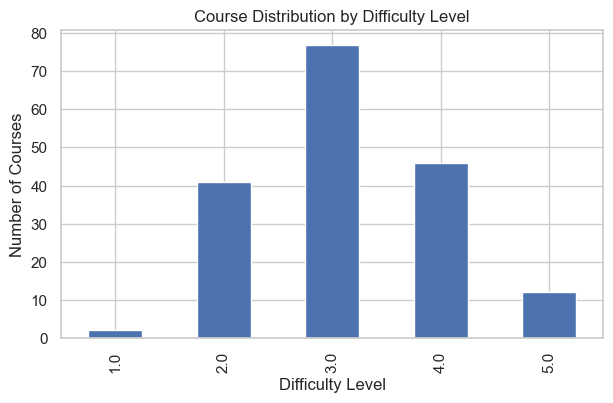

In [ ]:
difficulty_counts = courses["Difficulty_Level"].value_counts().sort_index()
difficulty_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Course Distribution by Difficulty Level"
)
plt.xlabel("Difficulty Level")
plt.ylabel("Number of Courses")
plt.show()

Course teaching styles

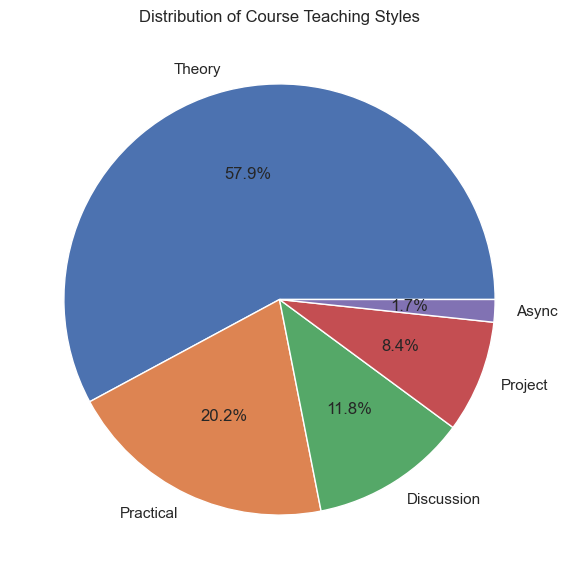

In [ ]:
teaching_counts = courses["Teaching_Style"].value_counts()
teaching_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    title="Distribution of Course Teaching Styles"
)
plt.ylabel("")
plt.show()

Course workload


Workload_Level
Medium    127
High       44
Low         7
Name: count, dtype: int64


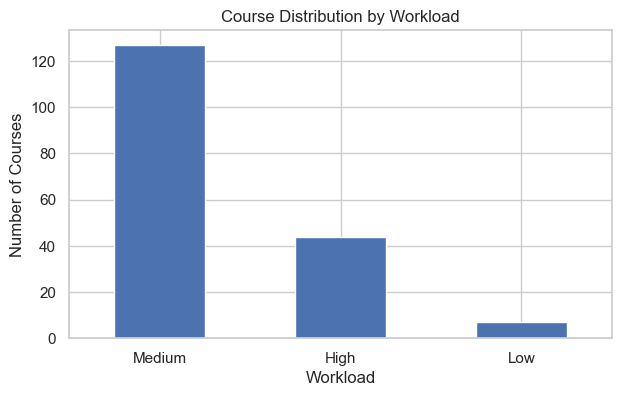

In [ ]:
workload_counts = courses["Workload_Level"].value_counts()
display(workload_counts)
workload_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Course Distribution by Workload"
)
plt.xlabel("Workload")
plt.ylabel("Number of Courses")
plt.xticks(rotation=0)
plt.show()

STUDENT COURSE INTERACTION ANALYSIS

Interaction type distribution


Interaction_Type
viewed         2526
shortlisted    1817
enrolled       1004
compared        269
wishlisted      104
dropped          35
Name: count, dtype: int64


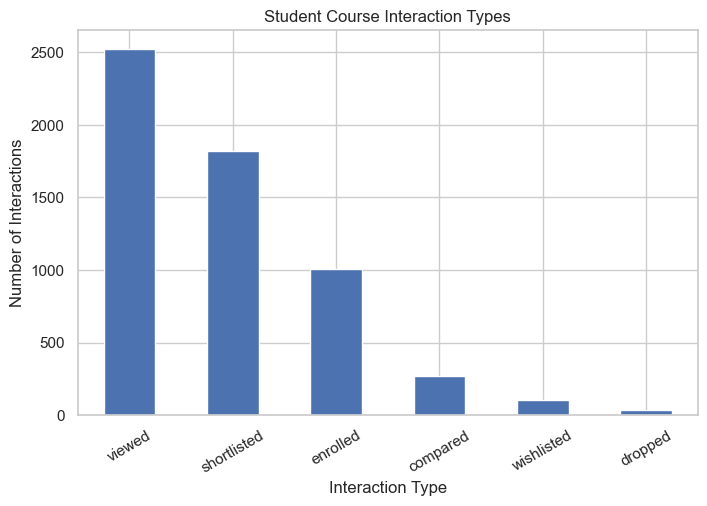

In [ ]:
# Standardization of Interaction_Type

interactions["Interaction_Type"] = (
    interactions["Interaction_Type"]
    .str.strip()
    .str.lower()
    .replace({
        "view": "viewed",
        "shortlist": "shortlisted",
        "enroll": "enrolled",
        "registered": "enrolled",
        "compare": "compared",
        "drop": "dropped",
        "withdrawn": "dropped"
    })
)

# Check standardized values
interaction_counts = interactions["Interaction_Type"].value_counts()
display(interaction_counts)
interaction_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Student Course Interaction Types"
)
plt.xlabel("Interaction Type")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=30)
plt.show()

Time spent exploring courses

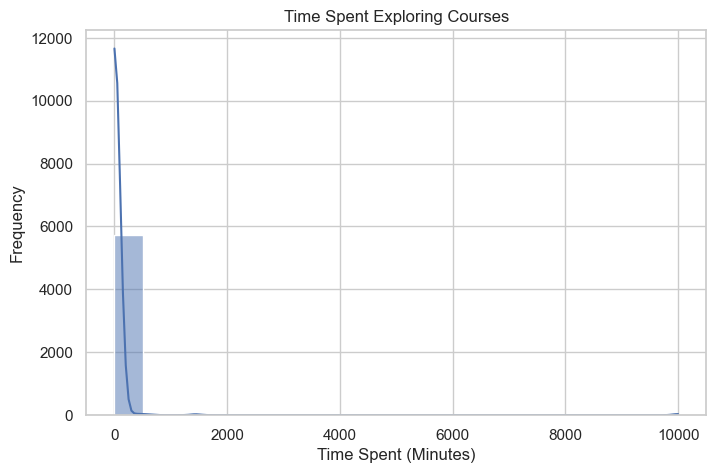

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=interactions,
    x="Time_Spent_Minutes",
    bins=20,
    kde=True
)
plt.title("Time Spent Exploring Courses")
plt.xlabel("Time Spent (Minutes)")
plt.ylabel("Frequency")
plt.show()

Rating distribution


Rating_Given
1.0     20
2.0     76
3.0    196
4.0    384
5.0    451
Name: count, dtype: int64


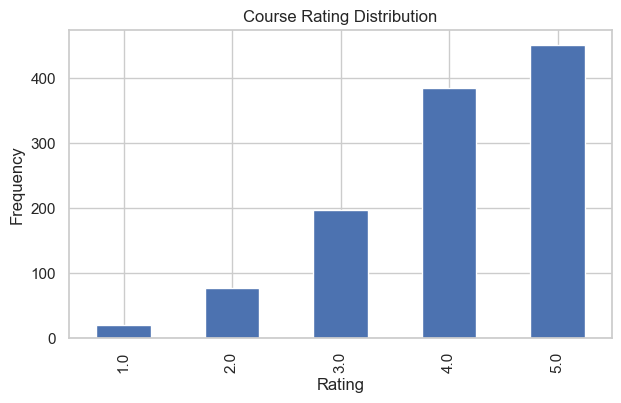

In [ ]:
rating_data = interactions.dropna(subset=["Rating_Given"])
rating_counts = rating_data["Rating_Given"].value_counts().sort_index()
display(rating_counts)
rating_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Course Rating Distribution"
)
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

Recommendation sources


Recommended_By
self-search      1839
friend           1156
senior           1117
faculty           747
online            623
Not Specified     230
advisor            36
Name: count, dtype: int64


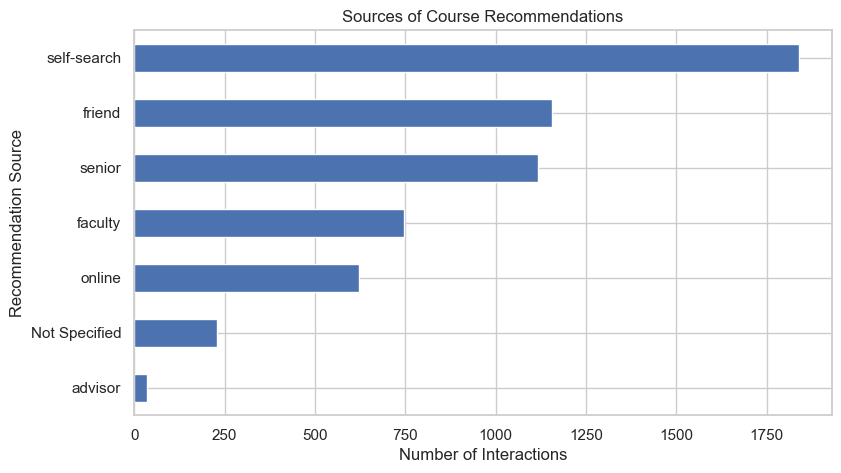

In [ ]:
# Standardization of Recommendation Sources

interactions["Recommended_By"] = (
    interactions["Recommended_By"]
    .str.strip()
    .str.lower()
    .replace({
        "self search": "self-search",
        "self": "self-search",
        "friends": "friend",
        "senior student": "senior",
        "seniors": "senior",
        "not specified": "Not Specified",
        "online (youtube/reddit)": "online",
        "youtube": "online",
        "reddit": "online",
        "faculty/advisor": "faculty",
        "faculty advisor" : "faculty",
        "unknown": "Not Specified",
        "-": "Not Specified",
        "reddit/youtube": "online"
    })
)

recommendation_counts = (
    interactions["Recommended_By"]
    .value_counts()
    .head(10)
)

display(recommendation_counts)

recommendation_counts.plot(
    kind="barh",
    figsize=(9, 5),
    title="Sources of Course Recommendations"
)

plt.xlabel("Number of Interactions")
plt.ylabel("Recommendation Source")
plt.gca().invert_yaxis()
plt.show()

Correlation Analysis

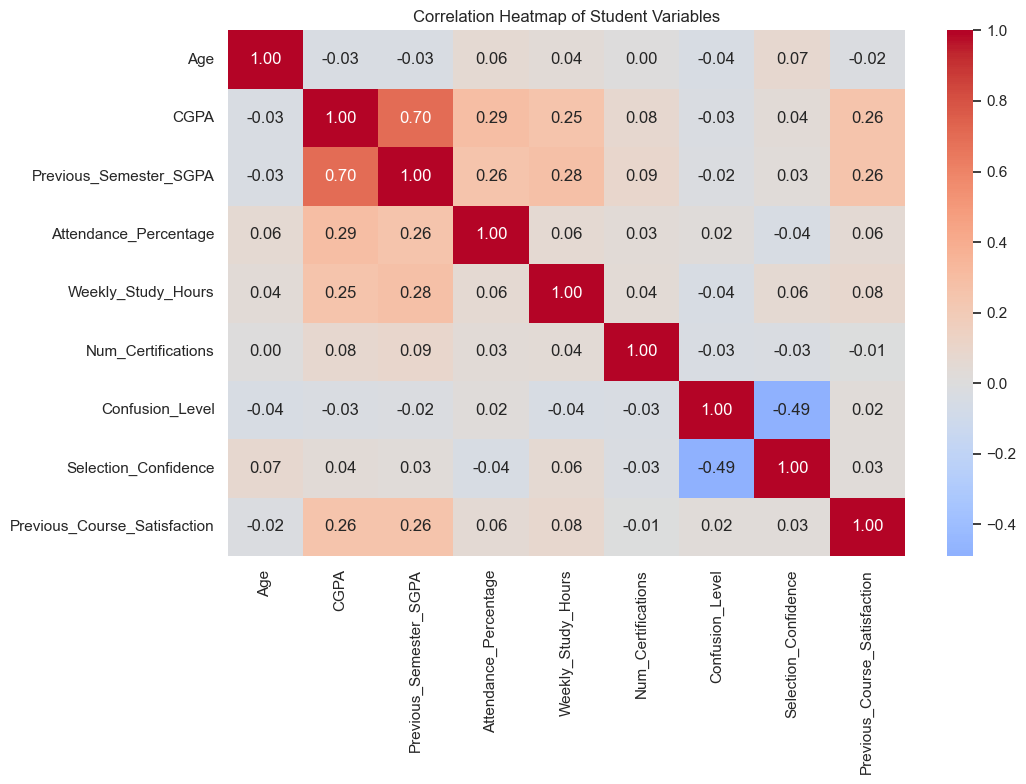

In [ ]:
correlation_cols = [
    "Age",
    "CGPA",
    "Previous_Semester_SGPA",
    "Attendance_Percentage",
    "Weekly_Study_Hours",
    "Num_Certifications",
    "Confusion_Level",
    "Selection_Confidence",
    "Previous_Course_Satisfaction"
]
correlation_data = students[correlation_cols].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlation Heatmap of Student Variables")
plt.tight_layout()
plt.show()

Statistical Analysis

Research question1:Is there a significant relationship between students' skill level and internship experience?

Hypotheses:

H₀: Skill level and internship experience are independent. H₁: Skill level and internship experience are associated.

In [ ]:
# contingency_table = pd.crosstab(
#     students["Skill_Level"],
#     students["Internship_Experience"]
# )

# display(contingency_table)
# chi2, p_value, dof, expected = chi2_contingency(
#     contingency_table
# )
# print("Chi-square statistic:", chi2)
# print("P-value:", p_value)
# print("Degrees of freedom:", dof)
# if p_value < 0.05:
#     print("Reject H0: Significant association found.")
# else:
#     print("Fail to reject H0: No significant association found.")

#formulae based approach to calculate chi-square statistic and p-value
import numpy as np
import pandas as pd
from scipy.stats import chi2 as chi2_dist

# Remove Unknown categories
data = students[
    (students["Internship_Experience"] != "Unknown") &
    (students["Skill_Level"] != "Unknown")
].dropna(subset=["Internship_Experience", "Skill_Level"])

# Observed frequency
observed = pd.crosstab(
    data["Skill_Level"],
    data["Internship_Experience"]
)

# Expected frequency manually
N = observed.values.sum()
row_totals = observed.sum(axis=1).values.reshape(-1, 1)
col_totals = observed.sum(axis=0).values.reshape(1, -1)

expected = (row_totals @ col_totals) / N

# Chi-square statistic manually
chi2_stat = np.sum(
    (observed.values - expected) ** 2 / expected
)

# Degrees of freedom
dof = (observed.shape[0] - 1) * (observed.shape[1] - 1)

# P-value
p_value = chi2_dist.sf(chi2_stat, dof)

print("Observed Frequencies:")
display(observed)

print("Expected Frequencies:")
display(pd.DataFrame(
    expected,
    index=observed.index,
    columns=observed.columns
))

print("Chi-square statistic:", chi2_stat)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

print("Minimum expected frequency:", expected.min())

if p_value < 0.05:
    print("Reject H0: Significant association found.")
else:
    print("Fail to reject H0: No significant association found.")


Observed Frequencies:



Internship_Experience,No,Yes
Skill_Level,,
Advanced,209,65
Beginner,182,35
Intermediate,325,75



Expected Frequencies:



Internship_Experience,No,Yes
Skill_Level,,
Advanced,220.184063,53.815937
Beginner,174.379349,42.620651
Intermediate,321.436588,78.563412



Chi-square statistic: 4.7891147865090815
Degrees of freedom: 2
P-value: 0.0912130414970055
Minimum expected frequency: 42.62065095398429
Fail to reject H0: No significant association found.



Research question2: Does average CGPA differ across student skill levels?

Hypotheses:

H₀: Mean CGPA is equal across skill levels. H₁: At least one skill level has a different mean CGPA.

In [ ]:
# skill_groups = []
# for skill in students["Skill_Level"].dropna().unique():
#     group = students.loc[
#         students["Skill_Level"] == skill,
#         "CGPA"
#     ].dropna()
#     if len(group) >= 2:
#         skill_groups.append(group)
# f_statistic, p_value = f_oneway(*skill_groups)
# print("ANOVA F-statistic:", f_statistic)
# print("P-value:", p_value)
# if p_value < 0.05:
#     print("Reject H0: At least one group mean differs.")
# else:
#     print("Fail to reject H0: Insufficient evidence of a difference.")

#formulae based approach to calculate ANOVA F-statistic and p-value
import numpy as np
import pandas as pd
from scipy.stats import f

# Create groups based on Skill_Level
skill_groups = []

for skill in students["Skill_Level"].dropna().unique():
    group = students.loc[
        students["Skill_Level"] == skill, "CGPA"
    ].dropna()

    if len(group) >= 2:
        skill_groups.append(group)

# Number of groups and total observations
k = len(skill_groups)
N = sum(len(group) for group in skill_groups)

# Calculate grand mean
grand_mean = sum(group.sum() for group in skill_groups) / N

# Calculate Between-Group Sum of Squares (SSB)
SSB = sum(
    len(group) * (group.mean() - grand_mean) ** 2
    for group in skill_groups
)

# Calculate Within-Group Sum of Squares (SSW)
SSW = sum(
    sum((group - group.mean()) ** 2)
    for group in skill_groups
)

# Degrees of freedom
df_between = k - 1
df_within = N - k

# Mean Squares
MSB = SSB / df_between
MSW = SSW / df_within

# Calculate F-statistic using formula
F_statistic = MSB / MSW

# Calculate p-value using F-distribution
p_value = f.sf(F_statistic, df_between, df_within)

print("Between Group SS (SSB):", SSB)
print("Within Group SS (SSW):", SSW)
print("Mean Square Between (MSB):", MSB)
print("Mean Square Within (MSW):", MSW)
print("F-statistic:", F_statistic)
print("P-value:", p_value)

# Hypothesis decision
if p_value < 0.05:
    print("Reject H0: At least one group mean differs.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")


Between Group SS (SSB): 180.10233579744724
Within Group SS (SSW): 944.5045192025533
Mean Square Between (MSB): 60.03411193248241
Mean Square Within (MSW): 0.9677300401665505
F-statistic: 62.03601153287572
P-value: 1.0298768616964685e-36
Reject H0: At least one group mean differs.



Additional relationship analysis

Confusion level versus selection confidence

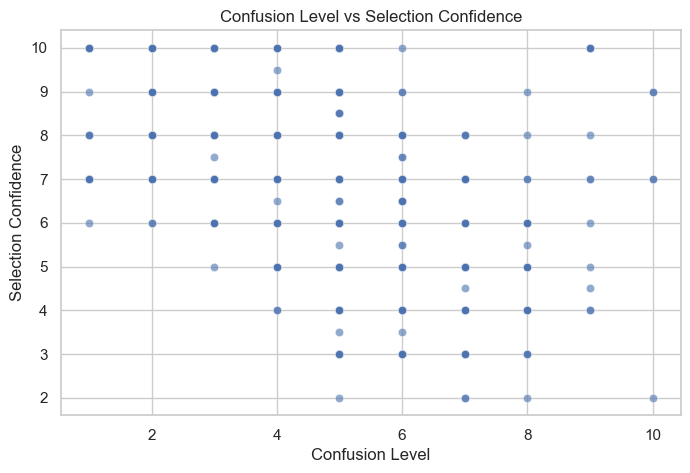


Spearman correlation: -0.524710370082146
P-value: 1.980728935319675e-70



In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=students,
    x="Confusion_Level",
    y="Selection_Confidence",
    alpha=0.6
)
plt.title("Confusion Level vs Selection Confidence")
plt.xlabel("Confusion Level")
plt.ylabel("Selection Confidence")
plt.show()
valid_data = students[
    ["Confusion_Level", "Selection_Confidence"]
].dropna()
correlation, p_value = stats.spearmanr(
    valid_data["Confusion_Level"],
    valid_data["Selection_Confidence"]
)
print("Spearman correlation:", correlation)
print("P-value:", p_value)

Generate key findings

In [ ]:
print("========== PROJECT KEY FINDINGS ==========")
print("\nTotal student records:", len(students))
print("Average CGPA:", round(students["CGPA"].mean(), 2))
print("Average attendance:",
      round(students["Attendance_Percentage"].mean(), 2))
print("Average study hours:",
      round(students["Weekly_Study_Hours"].mean(), 2))

print("\nMost common learning preference:")
print(students["Learning_Preference"].mode().iloc[0])

print("\nMost common skill level:")
print(students["Skill_Level"].mode().iloc[0])

print("\nMost selected course:")
print(students["Selected_Course_Code"].value_counts().index[0])

print("\nMost common interaction:")
print(interactions["Interaction_Type"].mode().iloc[0])


========== PROJECT KEY FINDINGS ==========

Total student records: 980
Average CGPA: 7.53
Average attendance: 79.3
Average study hours: 13.91

Most common learning preference:
hands-on/practical

Most common skill level:
Intermediate

Most selected course:
CSIB1002

Most common interaction:
viewed



PROJECT CONCLUSION

In [ ]:
# Conclusion

#The exploratory data analysis helped identify patterns in student demographics, academic performance, 
#interests, learning preferences and elective selection.

#The analysis also examined course catalogue characteristics and student interactions, providing insights 
#into how students explore and select elective courses.

#Statistical analysis was used to investigate relationships between selected student attributes.

#The project demonstrates how data cleaning, descriptive statistics, visualization and hypothesis testing 
#can help understand student elective-selection behaviour.

### Limitations

#1. The datasets are synthetic and do not represent actual student behaviour.
#2. Missing and inconsistent responses may affect certain analyses.
#3. Correlation does not establish causation.
#4. The analysis describes observed patterns and does not establish that a particular course is suitable for every student.

### Future Scope

#A future extension could develop a personalized elective recommendation system using student interests, academic performance, 
#skills and learning preferences.